# Module 3: Random Forest Classifier

step 1: re-load some of the variables used in previous modules:

promoter_1hot: (1000 x 800) feature matrix
y: ground-truth 1 / 0 expression classifier
X_train, X_test, y_train, y_test: matrix (promoter_1hot) and classifier train / test 80/20 splits
random_state = 42: seed for deterministic splits


In [18]:
# organize variables

import numpy as np
import pandas as pd

# load 1-hot encoded promoter file from file (2d array)
promoter_1hot = np.loadtxt("../data/promoters.1hot.csv", delimiter=",")
print(promoter_1hot.shape)

# load dataframe with metadata
df = pd.read_csv("../data/promoter_by_expression.csv")
print(df.head())

y = df['label'].values
print(f"X shape: {promoter_1hot.shape}")
print(f"y shape: {y.shape}")
print(f"Class balance: {y.mean():.2f} positive rate") # how many high expression / low expression promoters there are (?)

(1000, 800)
     gene_id                                           sequence  label  \
0  gene_0000  GTCGACGGATTCGCTATACGGTCCGATAAGTATAAAATAGTCGTCG...      1   
1  gene_0001  CTAAAAGATGTAGGGAACTATGCACATGAATATAAAGAACGATTCT...      1   
2  gene_0002  GACCACACGGACAAAGACGAAATGACAGCGTATAAAGGCAGAAGCT...      1   
3  gene_0003  GCGCAGTTGCCAGGTAAGTCTCTGATGCCATATAAACGGAAGCATG...      1   
4  gene_0004  AAGATCAACTACCTGAATAGCATACATTTGTATAAAAGTTACTGAC...      1   

   gc_content  tata_present  sequence_length  
0       0.375             1              200  
1       0.355             1              200  
2       0.380             1              200  
3       0.365             1              200  
4       0.345             1              200  
X shape: (1000, 800)
y shape: (1000,)
Class balance: 0.50 positive rate


In [19]:
# 3.2 Random forrest training skeleton

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split


rf = RandomForestClassifier(
    n_estimators=100,    # number of trees; start with 100
    max_features="sqrt",    # features considered per split; use 'sqrt'
    random_state=42,    # why does a random forest especially need this?
    n_jobs=-1            # use all CPU cores
)

# again split the train / test split. Same random state as in module 2, for consistency
X_train, X_test, y_train, y_test = train_test_split(
    promoter_1hot, y, test_size=0.2, random_state=42
)

# fit the rf model
rf.fit(X_train, y_train)

# Hard predictions and probability of class 1
rf_pred  = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)[:, 1] # get only the second column (probability of being 1, I believe?)

# Evaluate
rf_acc = accuracy_score(y_test, rf_pred)
rf_auc = roc_auc_score(y_test, rf_proba)

# Training-set accuracy, to check for overfitting
rf_train_acc = rf.score(X_train, y_train)

print(f"RF train accuracy: {rf_train_acc:.3f}")
print(f"RF test accuracy:  {rf_acc:.3f}   (LR: 0.895)")
print(f"RF test AUC:       {rf_auc:.3f}   (LR: 0.957)")

RF train accuracy: 1.000
RF test accuracy:  0.935   (LR: 0.895)
RF test AUC:       0.982   (LR: 0.957)


In [20]:
# Again, do the cross-validation

from sklearn.model_selection import cross_val_score

rf_cv = cross_val_score(
    RandomForestClassifier(n_estimators=100, max_features='sqrt',
                           random_state=42, n_jobs=-1),
    promoter_1hot, y,              # full dataset -- matches what I did in Module 2
    cv=5, scoring='roc_auc'
)
print("RF AUC per fold:", rf_cv.round(3))
print(f"RF CV mean: {rf_cv.mean():.3f}, std: {rf_cv.std():.3f}   (LR: 0.952 ± 0.011)")

RF AUC per fold: [0.989 0.969 0.964 0.952 0.959]
RF CV mean: 0.967, std: 0.012   (LR: 0.952 ± 0.011)


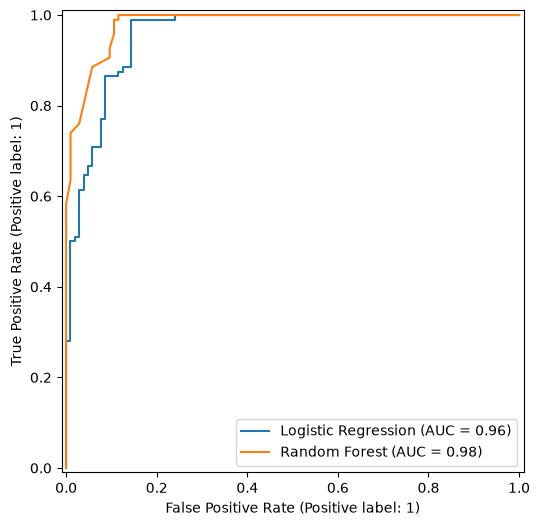

In [21]:
# Can I plot the ROC-AUC curves for LR and RF on the same graph?

import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay
from sklearn.linear_model import LogisticRegression

# Random Forest ROC Curve
#RocCurveDisplay.from_estimator(rf, X_test, y_test)

# Get the LR values
lr = LogisticRegression(random_state=42)
lr.fit(X_train, y_train)

# Plot both together
# Setup the plot figure and axes
fig, ax = plt.subplots(figsize=(8, 6))
#plot each on the same axis
RocCurveDisplay.from_estimator(lr, X_test, y_test, ax=ax, name="Logistic Regression")
RocCurveDisplay.from_estimator(rf, X_test, y_test, ax=ax, name="Random Forest")


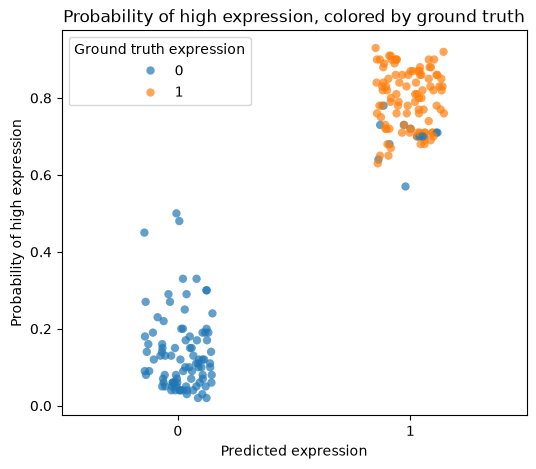

In [22]:
# Now I want to recreate the graph of confidence vs true assignment like I made in module 2

import matplotlib.pyplot as plt
import seaborn as sns

# make the df
prob_df = pd.DataFrame(rf_proba, columns=['P_high']) # probability of high expression
prob_df['pred'] = rf_pred # what the module guessed (high / low)
prob_df['ans'] = y_test # what the ground truth answer was

# plot
plt.figure(figsize = (6, 5))

sns.stripplot(
    data = prob_df,
    x='pred',
    y='P_high',
    jitter=0.15,
    alpha = 0.7,
    size=6,
    hue='ans'
)

plt.title("Probability of high expression, colored by ground truth")
plt.xlabel("Predicted expression")
plt.ylabel("Probability of high expression")
plt.legend(title="Ground truth expression")


In [23]:
# Pick optimal threshold

from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, rf_proba)

roc_df = pd.DataFrame({
    'fpr': fpr,
    'tpr': tpr,
    'threshold': thresholds
})

#print(roc_df.head(10))

# maximize true positve rate while minimizing false positve rate
optimal_idx = (tpr - fpr).argmax()
optimal_threshold = thresholds[optimal_idx]
print(f"Optimal threshold: {optimal_threshold:.3f}")
print(f"  TPR: {tpr[optimal_idx]:.3f}")
print(f"  FPR: {fpr[optimal_idx]:.3f}")


Optimal threshold: 0.630
  TPR: 1.000
  FPR: 0.115


In [24]:
# Create a scenario where RF (hopefully) blows LR out of the water

# The scenario: motif A + motif B are synergistic
    # when both are present high expression 100% of the time
    # when just A is present, high expression 60% of the time
    # when just B is present, high expression 10% of the time
    # when none are present, high expresssion 0% of the time

import numpy as np
import pandas as pd
from Bio.Seq import Seq
import os

os.makedirs("data", exist_ok=True)
rng = np.random.default_rng(seed=42)

# --- Biological parameters ---
N_GENES = 2000
PROMOTER_LENGTH = 200  # shortened for speed; real promoters ~1000bp

# Two real yeast transcription factor binding motifs
# TATA box (associated with high expression in many genes) -- Motif A
TATA_BOX = "TATAAA"
# BRE d motif (synergistically associated with the TATA box for expression, SSRCGCC) -- Motif B
BRED_MOTIF = "GGGCGCC"

# Poly-A stretch (associated with nucleosome positioning)
POLYA = "AAAAAA"

BASES = ['A', 'T', 'G', 'C']

# Generate random sequences, to be edited with future motifs
def random_sequence(length, rng, gc_content=0.38):
    """Generate a random DNA sequence with specified GC content."""
    at = (1 - gc_content) / 2
    gc = gc_content / 2
    probs = [at, at, gc, gc]  # A, T, G, C
    return ''.join(rng.choice(BASES, size=length, p=probs))

def insert_motif(seq, motif, position):
    """Insert a motif at a given position in a sequence string."""
    seq = list(seq)
    for i, base in enumerate(motif):
        seq[position + i] = base
    return ''.join(seq)

sequences = []
labels = []
metadata = []

# loop 2000 times for 
for i in range(N_GENES):
    seq = random_sequence(PROMOTER_LENGTH, rng)

    match i:
        case _ if i < 500: # A + B motifs
            seq = insert_motif(seq, TATA_BOX, position=30)
            seq = insert_motif(seq, BRED_MOTIF, position=60)
            label = 1
        case _ if i >= 500 and i < 1000: # A motif only
            seq = insert_motif(seq, TATA_BOX, position=30)
            if rng.random() < 0.6:
                label = 1
            else: 
                label = 0
        case _ if i >= 1000 and i < 1500: # B motif only
            seq = insert_motif(seq, BRED_MOTIF, position=60)
            if rng.random() < 0.1:
                label = 1
            else:
                label = 0
        case _ if i >= 1500: # no motifs
            label = 0 

    # add some randomly distributed noise
    if rng.random() < 0.1:
        seq = insert_motif(seq, POLYA, position=130)

    sequences.append(seq)
    labels.append(label)
    metadata.append(f"gene_{i:04d}")

# Save as FASTA
fasta_path = "../data/promoters.v2.fa"
with open(fasta_path, "w") as f:
    for name, seq in zip(metadata, sequences):
        f.write(f">{name}\n{seq}\n")

# Save labels
labels_df = pd.DataFrame({"gene_id": metadata, "high_expression": labels})
labels_df.to_csv("../data/expression.v2.tsv", sep="\t", index=False)

print(f"Generated {N_GENES} promoter sequences of length {PROMOTER_LENGTH}bp")
print(f"High expression: {sum(labels)}, Low expression: {N_GENES - sum(labels)}")
print(f"Files saved to data/")




Generated 2000 promoter sequences of length 200bp
High expression: 845, Low expression: 1155
Files saved to data/


In [25]:
# One-hot encode the new test data
from Bio import SeqIO
import numpy as np

def create_df(records, labels_df):
    rows = []
    for record in records:
        seq = str(record.seq)
        gene_id = record.id
        label = labels_df.loc[labels_df['gene_id'] == gene_id, 'high_expression'].values[0]
    
        tata_present = 1 if "TATAAA" in seq else 0
        gc_content = (seq.count("C") + seq.count("G")) / len(seq)
        seq_length = len(record.seq)
    
        rows.append({
            "gene_id": gene_id,
            "sequence": seq,
            "label": label,
            "gc_content": gc_content,
            "tata_present": tata_present,
            "sequence_length": seq_length
        })
    df = pd.DataFrame(rows)
    print(df.head())
    print(f"number tata: {len(df.loc[df['tata_present'] == 1])}")
    print(f"\nDataframe shape: {df.shape}")    
    return df

# one-hot encode function
def one_hot_encode(seq):
    mapping = {'A': 0, 'T': 1, 'G': 2, 'C': 3}
    matrix = np.zeros((len(seq), 4))

    # enumerate is needed to get the index from the string
    for index, base in enumerate(seq):
        # check regular base. If not, all zeros stay
        if base in mapping: 
            matrix[index, mapping.get(base)] = 1
    
    return matrix

# make a df out of the simulated data
records = list(SeqIO.parse("../data/promoters.v2.fa", "fasta"))
labels_df = pd.read_csv("../data/expression.v2.tsv", sep="\t")

df = create_df(records, labels_df)

result = np.stack(df['sequence'].apply(one_hot_encode))
print(f"result.shape: {result.shape}")
result = result.reshape(2000, -1)
print(f"size of final result: {result.shape}")

#save files from this module
np.savetxt("../data/promoters.1hot.v2.csv", result, delimiter=",")
df.to_csv("../data/promoter_by_expression.v2.csv", index=False)

     gene_id                                           sequence  label  \
0  gene_0000  GTCGACGGATTCGCTATACGGTCCGATAAGTATAAAATAGTCGTCG...      1   
1  gene_0001  CTAAAAGATGTAGGGAACTATGCACATGAATATAAAGAACGATTCT...      1   
2  gene_0002  GACCACACGGACAAAGACGAAATGACAGCGTATAAAGGCAGAAGCT...      1   
3  gene_0003  GCGCAGTTGCCAGGTAAGTCTCTGATGCCATATAAACGGAAGCATG...      1   
4  gene_0004  AAGATCAACTACCTGAATAGCATACATTTGTATAAAAGTTACTGAC...      1   

   gc_content  tata_present  sequence_length  
0       0.395             1              200  
1       0.380             1              200  
2       0.395             1              200  
3       0.385             1              200  
4       0.360             1              200  
number tata: 1153

Dataframe shape: (2000, 6)
result.shape: (2000, 200, 4)
size of final result: (2000, 800)


In [27]:
# re-test on the one-hot encoded data

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

# load 1-hot encoded promoter file from file (2d array)
promoter_1hot = np.loadtxt("../data/promoters.1hot.v2.csv", delimiter=",")

# load dataframe with metadata
df = pd.read_csv("../data/promoter_by_expression.v2.csv")
print(df.head())

y = df['label'].values
#print(f"X shape: {promoter_1hot.shape}")
#print(f"y shape: {y.shape}")
#print(f"Class balance: {y.mean():.2f} positive rate")
print()

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Cross validation for RF
# promoter_1hot is the 1-hot encoded promoter sequences, y is the ground truth high/low expression, cv of 5 means five folds
lr_cv = cross_val_score(
    LogisticRegression(random_state=42),
    promoter_1hot,
    y,
    cv=cv,
    scoring='roc_auc'
)

print("Logistic Regression Cross-Val Results")
print(f"AUC scores per fold: {lr_cv.round(3)}")
print(f"Mean AUC: {lr_cv.mean():.3f}")
print(f"Std AUC:  {lr_cv.std():.3f}")
print()

rf_cv = cross_val_score(
    RandomForestClassifier(n_estimators=100, max_features='sqrt',
                           random_state=42, n_jobs=-1),
    promoter_1hot, y,              # full dataset -- matches what I did in Module 2
    cv=cv, scoring='roc_auc'
)

print("Random Forrest Cross-Val Results")
print(f"AUC scores per fold: {rf_cv.round(3)}")
print(f"Mean AUC: {rf_cv.mean():.3f}")
print(f"Std AUC:  {rf_cv.std():.3f}")


     gene_id                                           sequence  label  \
0  gene_0000  GTCGACGGATTCGCTATACGGTCCGATAAGTATAAAATAGTCGTCG...      1   
1  gene_0001  CTAAAAGATGTAGGGAACTATGCACATGAATATAAAGAACGATTCT...      1   
2  gene_0002  GACCACACGGACAAAGACGAAATGACAGCGTATAAAGGCAGAAGCT...      1   
3  gene_0003  GCGCAGTTGCCAGGTAAGTCTCTGATGCCATATAAACGGAAGCATG...      1   
4  gene_0004  AAGATCAACTACCTGAATAGCATACATTTGTATAAAAGTTACTGAC...      1   

   gc_content  tata_present  sequence_length  
0       0.395             1              200  
1       0.380             1              200  
2       0.395             1              200  
3       0.385             1              200  
4       0.360             1              200  

Logistic Regression Cross-Val Results
AUC scores per fold: [0.865 0.873 0.84  0.881 0.854]
Mean AUC: 0.863
Std AUC:  0.014

Random Forrest Cross-Val Results
AUC scores per fold: [0.937 0.933 0.925 0.951 0.931]
Mean AUC: 0.936
Std AUC:  0.008


RF did not beat LR by as much as I assumed. One reason for this could be the additive nature of the motifs. Every weight that the LR model assigns to the motifs (the B motif specifically), pushes it in the right direction. Another good test (which I won't run right now), would be a negative synergy -- Both A and B motif are associated with an increased expression, but when they are combined they negatively interact for low expression. I assume this is where RF would really smoke LR.

When to use LR over RF if RF has won all of our tests so far. If the results are similar, often LR is better because it is more simple and the results are more interpretable. Each feature is assigned a weight and direction so you can see where the signal is coming from and can potentially make more biologically relevant statements.